<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS09/JS09_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS09 - Approximate Nearest Neighbors: Lab 2 (Exact NN vs. FAISS)

Percobaan pencarian sederhana menggunakan **FAISS**. Instalasi menggunakan FAISS-CPU (`pip install faiss-cpu`); jika ingin menggunakan GPU dapat melakukan instalasi FAISS-GPU.

> Pada venv lokal folder JS09, `faiss-cpu` sudah terinstal saat setup.


## Langkah 1 - Instal FAISS

In [1]:
# Install FAISS (jika belum terinstal):
# !pip install faiss-cpu    <- untuk Google Colab
# !pip install faiss-gpu    <- jika ingin menggunakan GPU
import faiss  # cek ketersediaan
print('faiss version:', faiss.__version__)

faiss version: 1.15.1


## Langkah 2 - Import Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

## Langkah 3 - Membuat Dummy Dataset

In [3]:
# Build random data
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 data 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query point

## Langkah 4 - Buat Model Exact NN

In [4]:
# Search NN using Exact NN
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

# Compute Exact NN Time
start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # Find 3 NN
end = time.time()
time_flat = end - start

## Langkah 5 - Buat Model FAISS (IVF + PQ)

Index IVF (inverted file) membagi data ke dalam `nlist` cluster; PQ (product quantization) mengompresi vektor menjadi `m` sub-vektor 8 bit sehingga pencarian menjadi approximate dan hemat memori.

In [5]:
# Compute FAISS
nlist = 10   # n-cluster (inverted list)
m = 2        # number of subvector
quantizer = faiss.IndexFlatL2(2)   # used by IVF for initiatl cluster
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

## Langkah 6 - Cek Hasil Performa

In [6]:
# Print The Peformances
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.0018324851989746094
Waktu IVF+PQ: 0.0009970664978027344


FAISS (IVF+PQ) dapat mengungguli exact NN dengan nilai yang tipis. Namun ingat, kita belum mencoba dengan data yang lebih besar. Data dummy yang digunakan hanya 1000 titik 2D.

## Langkah 7 - Visualisasi

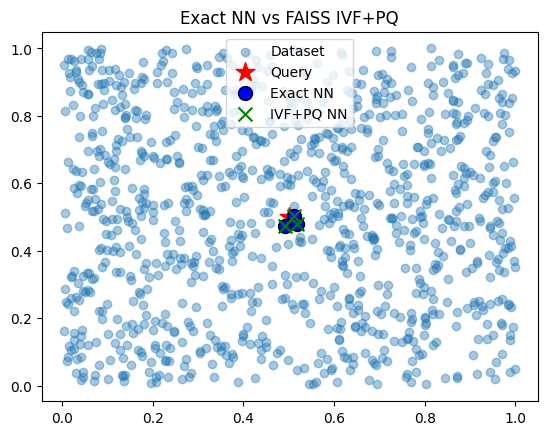

In [7]:
# Visualize
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Dataset")
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label="Query")

# Flat NN -> Exact NN
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=100, edgecolor='k', label="Exact NN")

# IVF+PQ NN -> FAISS
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Exact NN vs FAISS IVF+PQ")
plt.show()

Pada data kecil ini FAISS IVF+PQ menemukan tetangga yang sama dengan exact NN - hasil *approximate* dan *exact* bertepatan. Perbedaan kecepatan akan semakin jelas pada data berukuran besar (lihat Lab 4 dan Lab 5).